In [137]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# from google.colab import drive
# drive.mount('/content/drive')

In [114]:
data_path_pre = '../ronaldo-top/ronaldo-top_preprocessed.csv'
data = pd.read_csv(data_path_pre)
data.shape

(564, 16)

In [115]:
data.head(1)

,conversation_id_str,created_at,favorite_count,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username,text_original,text_clean
0,2106927418057310298,2026-10-05T02:00:15.000Z,4690,2106927418057310298,https://pbs.twimg.com/amplify_video_thumb/2106...,NaN,en,NaN,120,258,804,https://x.com/afc_Ade1/status/2106927418057310298,2080781657766805505,afc_Ade1,Ronaldo needs to find a way to get this video ...,Ronaldo needs to find a way to get this video ...


In [116]:
data[["conversation_id_str", "created_at", "favorite_count", "text_original", "text_clean"]].head(8)

,conversation_id_str,created_at,favorite_count,text_original,text_clean
0,2106927418057310298,2026-10-05T02:00:15.000Z,4690,Ronaldo needs to find a way to get this video ...,Ronaldo needs to find a way to get this video ...
1,2107388414811361592,2026-10-06T08:32:06.000Z,2916,One player doesn’t make a team but 75% of the ...,One player doesn’t make a team but 75% of the ...
2,2107179851425649058,2026-10-05T18:43:20.000Z,1861,"If you like, let anyone whine you about Ronald...","If you like, let anyone whine you about Ronald..."
3,2107837996003402032,2026-10-07T14:18:34.000Z,1470,"Cristiano Ronaldo: ""Please be nice about me Jo...","Cristiano Ronaldo: ""Please be nice about me Jo..."
4,2107805832868245890,2026-10-07T12:10:46.000Z,367,Cristiano Ronaldo - Goal Catalogue\n\n[@Cristi...,Cristiano Ronaldo - Goal Catalogue [@Cristiano...
5,2106078375164907767,2026-10-02T17:46:28.000Z,6515,Ronaldo really went on to protest after he tri...,Ronaldo really went on to protest after he tri...
6,2107772425693765781,2026-10-07T09:58:01.000Z,678,Messi doesn’t even play in Saudi Arabia and st...,Messi doesn’t even play in Saudi Arabia and st...
7,2107806687046549563,2026-10-07T12:14:10.000Z,351,"Remove the World cup Messi won over Ronaldo, t...","Remove the World cup Messi won over Ronaldo, t..."


In [117]:
data_path_sentiment = '../sentimen/ronaldo_labeled.csv'
data_label = pd.read_csv(data_path_sentiment)
data_label.shape

(565, 3)

In [118]:
data_label.head(1)

,text_clean,sentimen,confidence
0,as my final act of love for ronaldo i will bec...,Positive,0.835588


In [119]:
pd.to_datetime(data['created_at']).dt.hour.head(5)

0     2
1     8
2    18
3    14
4    12
Name: created_at, dtype: int32

In [120]:
data['posting_hour'] = data['text_clean'].str.split().str.len()
data['has_image'] = data['image_url'].notna().astype(int)
data['text_length'] = data['text_clean'].fillna('').astype(str).str.len()
data['word_count'] = data['text_clean'].fillna('').astype(str).str.split().str.len()

In [121]:
data['sentiment_code'] = data_label['sentimen'].astype('category').cat.codes
data

,conversation_id_str,created_at,favorite_count,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,...,tweet_url,user_id_str,username,text_original,text_clean,posting_hour,has_image,text_length,word_count,sentiment_code
0,2106927418057310298,2026-10-05T02:00:15.000Z,4690,2106927418057310298,https://pbs.twimg.com/amplify_video_thumb/2106...,NaN,en,NaN,120,258,...,https://x.com/afc_Ade1/status/2106927418057310298,2080781657766805505,afc_Ade1,Ronaldo needs to find a way to get this video ...,Ronaldo needs to find a way to get this video ...,27,1,123,27,2
1,2107388414811361592,2026-10-06T08:32:06.000Z,2916,2107388414811361592,https://pbs.twimg.com/amplify_video_thumb/2107...,NaN,en,NaN,39,97,...,https://x.com/ChessLordK/status/21073884148113...,1612844910369030145,ChessLordK,One player doesn’t make a team but 75% of the ...,One player doesn’t make a team but 75% of the ...,27,1,149,27,0
2,2107179851425649058,2026-10-05T18:43:20.000Z,1861,2107179851425649058,https://pbs.twimg.com/amplify_video_thumb/2107...,NaN,en,NaN,51,125,...,https://x.com/buzor042_/status/210717985142564...,1561968071547420674,buzor042_,"If you like, let anyone whine you about Ronald...","If you like, let anyone whine you about Ronald...",23,1,129,23,1
3,2107837996003402032,2026-10-07T14:18:34.000Z,1470,2107837996003402032,https://pbs.twimg.com/amplify_video_thumb/2107...,NaN,en,NaN,52,36,...,https://x.com/FootballRamble/status/2107837996...,19393128,FootballRamble,"Cristiano Ronaldo: ""Please be nice about me Jo...","Cristiano Ronaldo: ""Please be nice about me Jo...",12,1,75,12,2
4,2107805832868245890,2026-10-07T12:10:46.000Z,367,2107805832868245890,https://pbs.twimg.com/amplify_video_thumb/1997...,NaN,en,NaN,2,7,...,https://x.com/MohUtd_/status/2107805832868245890,1662475776711618560,MohUtd_,Cristiano Ronaldo - Goal Catalogue\n\n[@Cristi...,Cristiano Ronaldo - Goal Catalogue [@Cristiano...,8,1,58,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
559,2107353663396069630,2026-10-06T06:14:00.000Z,244,2107353663396069630,https://pbs.twimg.com/amplify_video_thumb/2107...,NaN,en,NaN,4,72,...,https://x.com/ELLIOTTTTFC/status/2107353663396...,1268931516844740619,ELLIOTTTTFC,🚨EXCL: Cristiano Ronaldo opens up why he wants...,EXCL: Cristiano Ronaldo opens up why he wants ...,47,1,264,47,0
560,2108023082099396682,2026-10-08T02:34:02.000Z,0,2108023082099396682,NaN,NaN,en,NaN,0,0,...,https://x.com/unmessy_22/status/21080230820993...,1263507756679483392,unmessy_22,"messi , maradona, pele sitting at the same tab...","messi , maradona, pele sitting at the same tab...",30,0,163,30,0
561,2107757291571232793,2026-10-07T08:57:53.000Z,1170,2107757291571232793,NaN,NaN,en,NaN,16,41,...,https://x.com/RayToluAyo/status/21077572915712...,315834089,RayToluAyo,Out of everything Cristiano Ronaldo said in hi...,Out of everything Cristiano Ronaldo said in hi...,50,0,274,50,1
562,2107951551381643467,2026-10-07T21:49:48.000Z,0,2107951551381643467,NaN,NaN,en,NaN,0,1,...,https://x.com/adekunleyshittu/status/210795155...,265015639,adekunleyshittu,"Ronaldo has endured criticism, setbacks and di...","Ronaldo has endured criticism, setbacks and di...",39,0,246,39,0


In [48]:
kolom_pilihan = [
    'favorite_count',
    'retweet_count',
    'reply_count',
    'quote_count',
    'text_length',
    'word_count',
    'posting_hour',
    'has_image',
    'sentiment_code'
]

df_fitur = data[kolom_pilihan].copy()

df_fitur.to_csv('data_regresi_twitter.csv', index=False)

print("File 'data_regresi_twitter.csv'")
print(df_fitur.head(3))

File 'data_regresi_twitter.csv'
   favorite_count  retweet_count  reply_count  quote_count  text_length  \
0            4690            804          258          120          123   
1            2916            682           97           39          149   
2            1861            335          125           51          129   

   word_count  posting_hour  has_image  sentiment_code  
0          27            27          1               2  
1          27            27          1               0  
2          23            23          1               1  


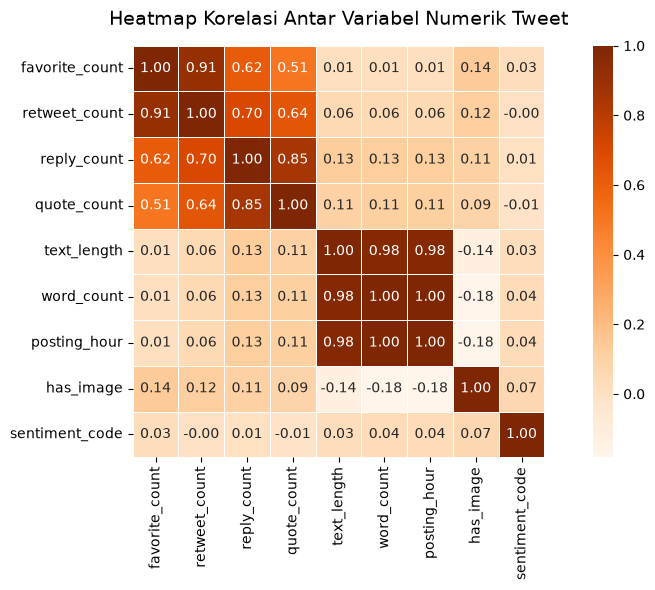

In [106]:
matriks_korelasi = df_fitur.corr(method='pearson')

plt.figure(figsize=(10, 6))
sns.heatmap(
    matriks_korelasi,
    annot=True,
    cmap='Oranges',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title('Heatmap Korelasi Antar Variabel Numerik Tweet', fontsize=14, pad=15)
plt.tight_layout()
plt.savefig('./img/heatmap_korelasi.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
threshold = 0.80

sol = matriks_korelasi.where(np.triu(np.ones(matriks_korelasi.shape), k=1).astype(bool))

pasangan_korelasi = sol.unstack().dropna()
data_pasangan = pasangan_korelasi.reset_index()
data_pasangan.columns = ['Variabel_1', 'Variabel_2', 'Nilai_Korelasi']
data_pasangan['Korelasi_Absolut'] = data_pasangan['Nilai_Korelasi'].abs()

df_terurut = data_pasangan.sort_values(by='Korelasi_Absolut', ascending=False).drop(columns=['Korelasi_Absolut'])

multikolinearitas = df_terurut[df_terurut['Nilai_Korelasi'].abs() >= threshold]

print("Pasangan Variabel Terurut Berdasarkan Korelasi Tertinggi")
print(df_terurut.to_string(index=False))

print(f"\nPasangan Variabel Terindikasi Multikolinearitas (|r| >= {threshold})")
print(multikolinearitas.to_string(index=False))

df_terurut.to_csv('./korelasi_terurut.csv', index=False)
multikolinearitas.to_csv('./cek_multikolinearitas.csv', index=False)

Pasangan Variabel Terurut Berdasarkan Korelasi Tertinggi
    Variabel_1     Variabel_2  Nilai_Korelasi
  posting_hour     word_count        1.000000
  posting_hour    text_length        0.981320
    word_count    text_length        0.981320
 retweet_count favorite_count        0.910897
   quote_count    reply_count        0.850297
   reply_count  retweet_count        0.704944
   quote_count  retweet_count        0.642424
   reply_count favorite_count        0.618243
   quote_count favorite_count        0.509929
     has_image   posting_hour       -0.182146
     has_image     word_count       -0.182146
     has_image favorite_count        0.140344
     has_image    text_length       -0.135704
   text_length    reply_count        0.130868
    word_count    reply_count        0.126128
  posting_hour    reply_count        0.126128
     has_image  retweet_count        0.121967
  posting_hour    quote_count        0.113695
    word_count    quote_count        0.113695
   text_length    quote

In [ ]:
X = data[['posting_hour','text_length','favorite_count',
        'reply_count','quote_count','has_image','sentiment_code']]
X = sm.add_constant(X)

vif = pd.DataFrame({
    'Variabel': X.columns,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
print(vif)

vif.to_csv('./cek_multikolinearitas_vif.csv', index=False)

         Variabel        VIF
0           const   1.000000
1    posting_hour  29.317747
2     text_length  28.860117
3  favorite_count   1.647751
4     reply_count   4.404223
5     quote_count   3.652520
6       has_image   1.125609
7  sentiment_code   1.011911


# Regresi

In [ ]:
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression

In [140]:
dataset = pd.read_csv('./data_regresi_twitter.csv')
dataset

,favorite_count,retweet_count,reply_count,quote_count,text_length,word_count,posting_hour,has_image,sentiment_code
0,4690,804,258,120,123,27,27,1,2
1,2916,682,97,39,149,27,27,1,0
2,1861,335,125,51,129,23,23,1,1
3,1470,323,36,52,75,12,12,1,2
4,367,64,7,2,58,8,8,1,1
...,...,...,...,...,...,...,...,...,...
559,244,202,72,4,264,47,47,1,0
560,0,0,0,0,163,30,30,0,0
561,1170,284,41,16,274,50,50,0,1
562,0,0,1,0,246,39,39,0,0


In [141]:
X = dataset[['favorite_count', 'has_image', 'word_count']]
y = dataset['retweet_count']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

b0 = model.intercept_
b1 = model.coef_[0]
b2 = model.coef_[1]
b4 = model.coef_[2]

In [142]:
print(f"Intersep : {b0:.2f}")
print(f"favorit : {b1:.2f}")
print(f"ada gambar : {b2:.2f}")
print(f"word : {b4:.2f}")
print(f"mae : {mae:.2f}")
print(f"r2 : {r2:.2f}")

Intersep : -50.59
favorit : 0.07
ada gambar : 32.75
word : 3.68
mae : 196.53
r2 : 0.89


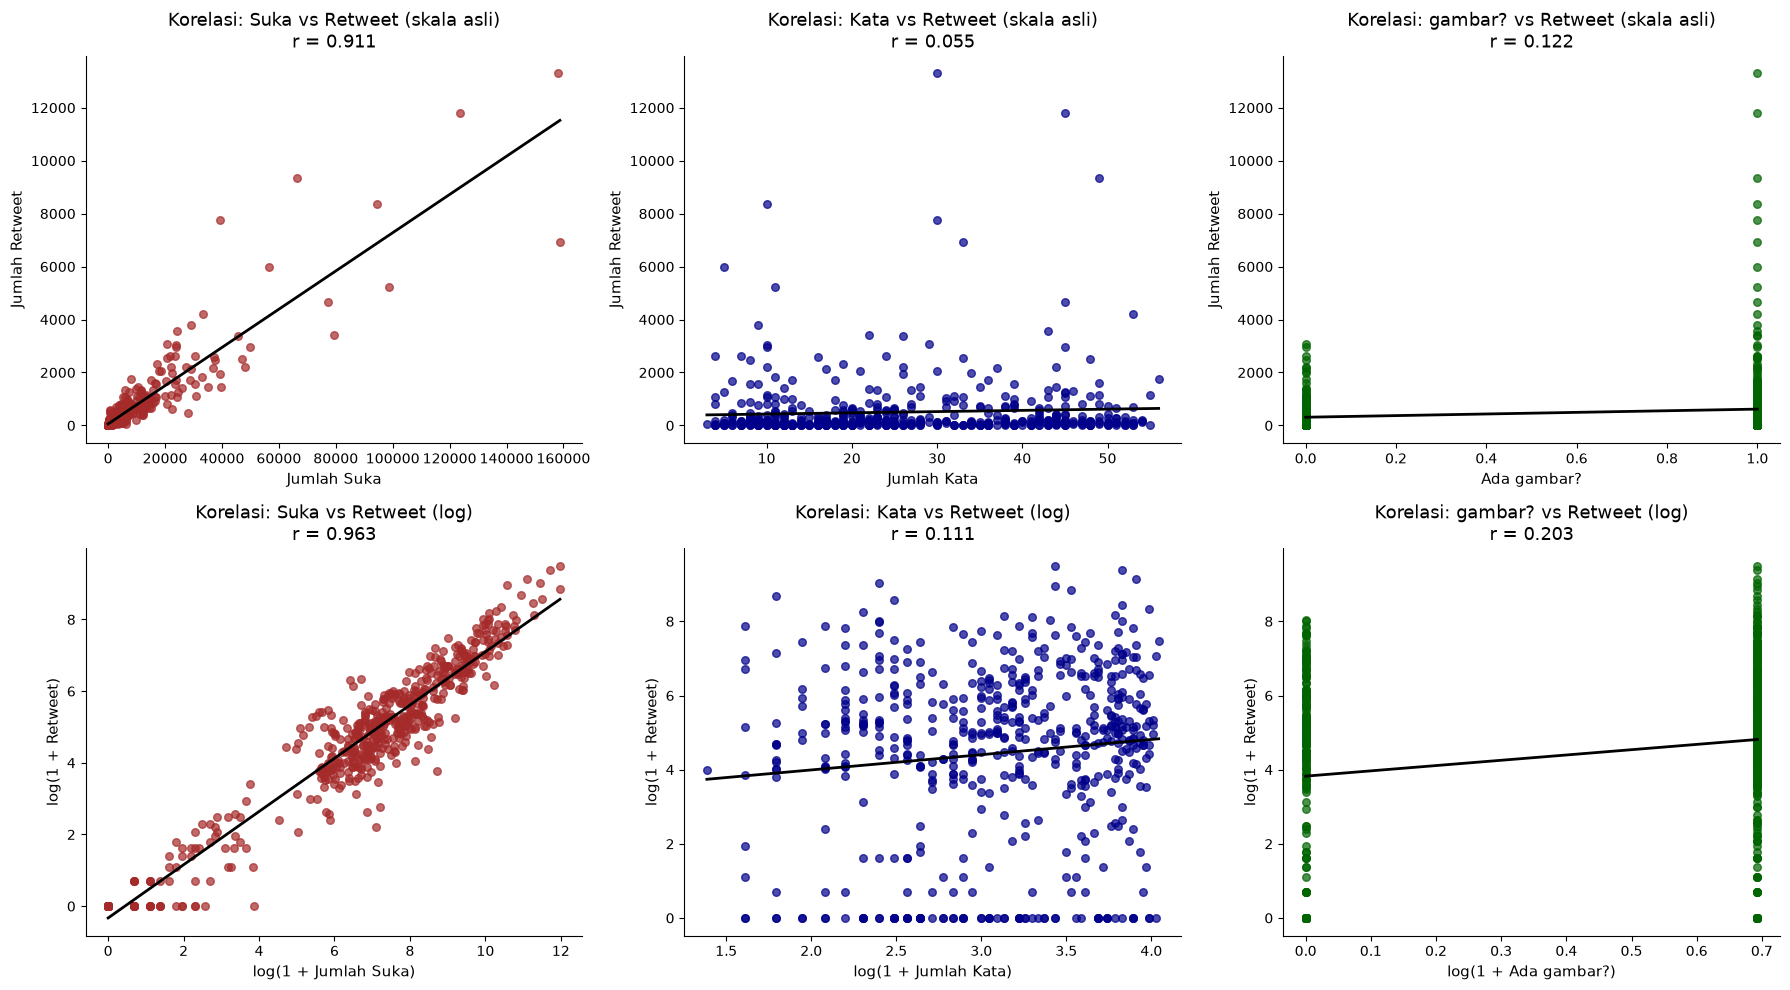

In [149]:
cols = ['favorite_count', 'word_count', 'has_image', 'retweet_count']
dataset = dataset[cols].replace([np.inf, -np.inf], np.nan).dropna().copy()

for c in cols:
    dataset[c + '_log'] = np.log1p(dataset[c])

vars_x = [
    ('favorite_count', 'Jumlah Suka', 'brown'),
    ('word_count',    'Jumlah Kata',    'darkblue'),
    ('has_image',    'Ada gambar?',    'darkgreen'),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for j, (col, label, warna) in enumerate(vars_x):
    sns.regplot(
        data=dataset, x=col, y='retweet_count', ci=None, color=warna,
        scatter_kws={'s': 30, 'alpha': 0.7},
        line_kws={'color': 'black', 'linewidth': 2},
        ax=axes[0, j]
    )
    r = dataset[col].corr(dataset['retweet_count'])
    axes[0, j].set_title(f"Korelasi: {label.split()[-1]} vs Retweet (skala asli)\nr = {r:.3f}", fontsize=13)
    axes[0, j].set_xlabel(label, fontsize=11)
    axes[0, j].set_ylabel("Jumlah Retweet", fontsize=11)

    sns.regplot(
        data=dataset, x=col + '_log', y='retweet_count_log', ci=None, color=warna,
        scatter_kws={'s': 30, 'alpha': 0.7},
        line_kws={'color': 'black', 'linewidth': 2},
        ax=axes[1, j]
    )
    r_log = dataset[col + '_log'].corr(dataset['retweet_count_log'])
    axes[1, j].set_title(f"Korelasi: {label.split()[-1]} vs Retweet (log)\nr = {r_log:.3f}", fontsize=13)
    axes[1, j].set_xlabel(f"log(1 + {label})", fontsize=11)
    axes[1, j].set_ylabel("log(1 + Retweet)", fontsize=11)

sns.despine()

plt.tight_layout()
plt.savefig('./img/grafik_korelasi.png', dpi=300, bbox_inches='tight')
plt.show()

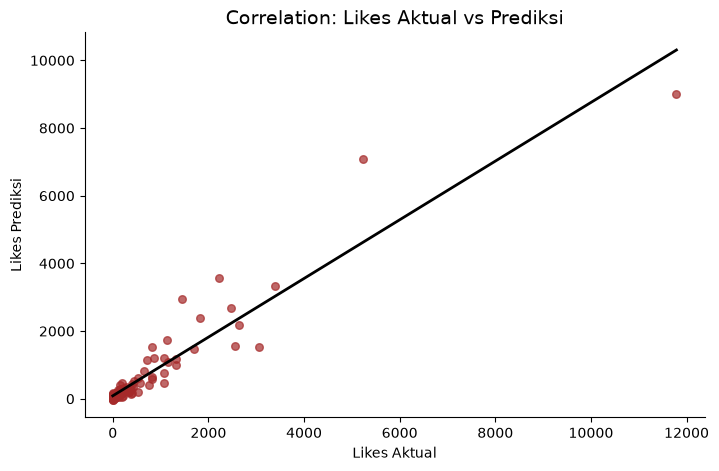

In [151]:

plt.figure(figsize=(8, 5))

sns.regplot(
    x=y_test,
    y=y_pred,
    ci=None,
    color='brown',
    scatter_kws={'s': 30, 'alpha': 0.7},
    line_kws={'color': 'black', 'linewidth': 2}
)

sns.despine()

plt.title("Correlation: Likes Aktual vs Prediksi", fontsize=14)
plt.xlabel("Likes Aktual")
plt.ylabel("Likes Prediksi")
plt.savefig('./img/grafik_korelasi_prediksi.png', dpi=300, bbox_inches='tight')

plt.show()

In [134]:
import joblib
joblib.dump(model, 'model_regresi.pkl')

['model_regresi.pkl']